In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

In [2]:
df_temp = pd.read_csv('../Part1_analysis/target_temp_NE_quadr_moanom.csv')
df_precip = pd.read_csv('../Part1_analysis/target_precip_NE_lin_moanom.csv')

In [3]:
temp_nao_corrs = np.zeros(7)
precip_nao_corrs = np.zeros(7)
for i in range(7):
    df_nao = pd.read_csv('../Part1_analysis/NAO_week'+str(i)+'.csv')
    temp_nao_corrs[6-i] = spearmanr(df_temp[:5040]['t2m'], df_nao[:5040]['nao_index']).statistic
    precip_nao_corrs[6-i] = spearmanr(df_precip[:5040]['tp'], df_nao[:5040]['nao_index']).statistic

In [4]:
temp_u10_corrs = np.zeros(7)
precip_u10_corrs = np.zeros(7)
for i in range(7):
    df_u10 = pd.read_csv('../Part1_analysis/u10_60N_week'+str(i)+'.csv')
    temp_u10_corrs[6-i] = spearmanr(df_temp[:5040]['t2m'], df_u10[:5040]['u10_60N']).statistic
    precip_u10_corrs[6-i] = spearmanr(df_precip[:5040]['tp'], df_u10[:5040]['u10_60N']).statistic

In [5]:
temp_sm_corrs = np.zeros(7)
precip_sm_corrs = np.zeros(7)
for i in range(7):
    df_sm = pd.read_csv('../Part1_analysis/sm_upper_NE_week'+str(i)+'_detr.csv')
    temp_sm_corrs[6-i] = spearmanr(df_temp[:5040]['t2m'], df_sm[:5040]['soil_moist_upper']).statistic
    precip_sm_corrs[6-i] = spearmanr(df_precip[:5040]['tp'], df_sm[:5040]['soil_moist_upper']).statistic

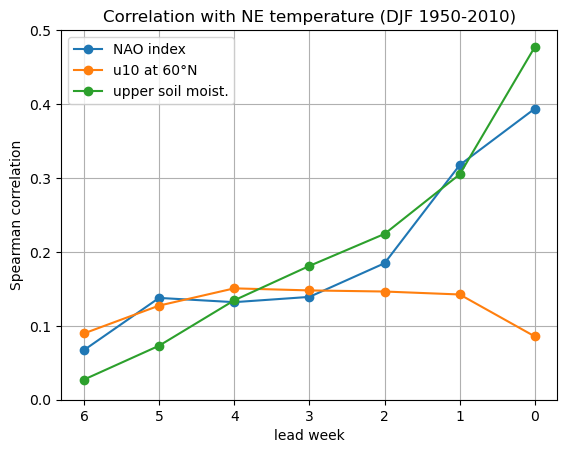

In [7]:
plt.plot(temp_nao_corrs,'o-', label='NAO index')
plt.plot(temp_u10_corrs,'o-', label='u10 at 60°N')
plt.plot(temp_sm_corrs,'o-', label='upper soil moist.')
plt.ylim((0,0.5))
plt.xticks(range(7), labels=[6,5,4,3,2,1,0])
plt.xlabel('lead week')
plt.ylabel('Spearman correlation')
plt.legend()
plt.title('Correlation with NE temperature (DJF 1950-2010)')
plt.grid()
plt.savefig('NE_temp_crosscorr.pdf', bbox_inches='tight')

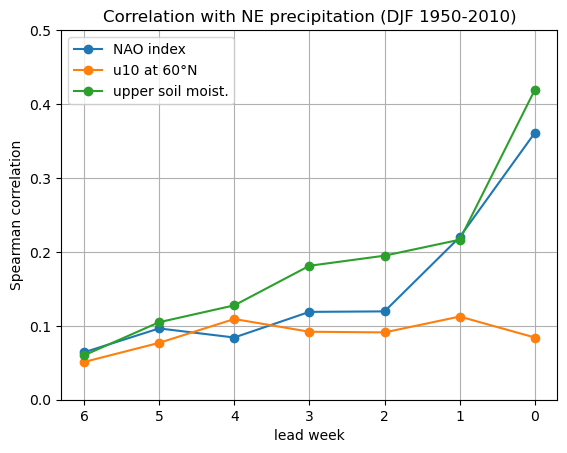

In [34]:
plt.plot(precip_nao_corrs,'o-', label='NAO index')
plt.plot(precip_u10_corrs,'o-', label='u10 at 60°N')
plt.plot(precip_sm_corrs,'o-', label='upper soil moist.')
plt.ylim((0,0.5))
plt.xticks(range(7), labels=[6,5,4,3,2,1,0])
plt.xlabel('lead week')
plt.ylabel('Spearman correlation')
plt.legend()
plt.title('Correlation with NE precipitation (DJF 1950-2010)')
plt.grid()
plt.savefig('NE_precip_crosscorr.png', bbox_inches='tight')